In [1]:
import sys
from pathlib import Path
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt
import math, cmath
import sys
import os
import joblib
from pathlib import Path
import pickle
import time
from mpl_toolkits.mplot3d import Axes3D
from scipy.sparse import csr_matrix, coo_matrix,  bmat, diags, identity, issparse, vstack, hstack

In [2]:
#import sys  
sys.path.insert(1,'C:\\Users\\avani\\Desktop\\Spin_Splitting_Ge_ABS')

In [3]:
import Minimal_Model_1D as M
import Minimal_model_1D_1sub as M1sub

In [4]:
hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

In [17]:
NSM = 1          # in nm
MY = 2              # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0          # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

MEFF = 0.023

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

MU_const = 0.8 + OMEGA/2

#ALPHAT = 50
#ALPHAT = 40
ALPHAT = 0

first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919


plotting band spectrum

In [18]:
NUM = 501
KX = np.linspace(-np.pi/10,np.pi/10,NUM)
Ep = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT, DELTA, MEFF,  MU_const,  phi=PHI, px=True, kx0=KX[i])

    Hli = Fli.H_p()

    Eli, Vli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=True)
        
    #Eli = np.sort(Eli)

    #print(Eli.shape)    
    #Eli = np.sort(Eli)
    
    Ep[i,:] = Eli

    if i%5 == 0:
        print(i)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150
155
160
165
170
175
180
185
190
195
200
205
210
215
220
225
230
235
240
245
250
255
260
265
270
275
280
285
290
295
300
305
310
315
320
325
330
335
340
345
350
355
360
365
370
375
380
385
390
395
400
405
410
415
420
425
430
435
440
445
450
455
460
465
470
475
480
485
490
495
500


In [7]:
Ep.shape

(501, 5)

In [85]:
print(Ep[0,:])

[  -627.54484957    815.60943293 -15315.81665229  16916.16736904 -25383.88880926]


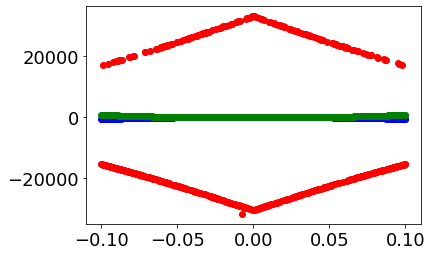

In [86]:
plt.scatter(KX/np.pi,Ep[:,0], color='blue')
plt.scatter(KX/np.pi,Ep[:,1], color = 'green')
plt.scatter(KX/np.pi,Ep[:,2], color = 'red')



In [19]:
NUM = 501
KX = np.linspace(-np.pi/10,np.pi/10,NUM)
EpM = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, px=True)
            
    Hli = Fli.HN(so = 'li', kx=KX[i])

    Eli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=False)
        
    Eli = np.sort(Eli)

    #print(Eli.shape)    
    #Eli = np.sort(Eli)
    
    EpM[i,:] = Eli

    if i%5 == 0:

        print(i)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150
155
160
165
170
175
180
185
190
195
200
205
210
215
220
225
230
235
240
245
250
255
260
265
270
275
280
285
290
295
300
305
310
315
320
325
330
335
340
345
350
355
360
365
370
375
380
385
390
395
400
405
410
415
420
425
430
435
440
445
450
455
460
465
470
475
480
485
490
495
500


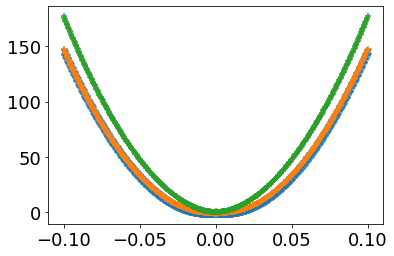

In [88]:
plt.scatter(KX/np.pi,EpM[:,0], marker='x')
plt.scatter(KX/np.pi,EpM[:,1], marker= '+')
plt.scatter(KX/np.pi,EpM[:,2], marker= '+')

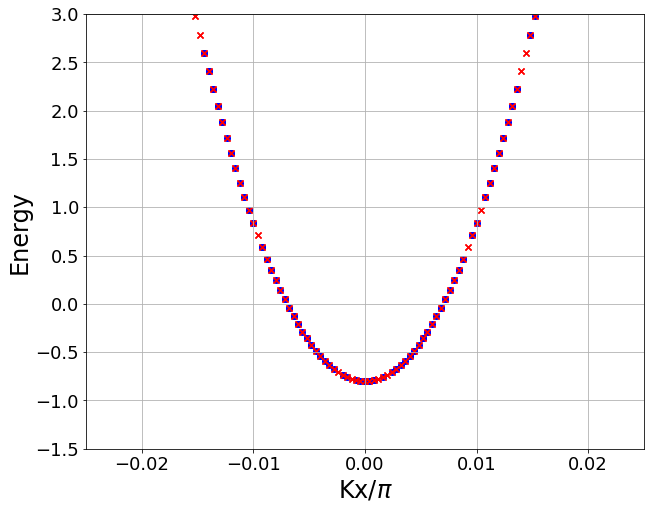

In [20]:
#alpha = 50 
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.ylim(ymin=-1.5)
plt.ylim(ymax=3)

plt.xlim(xmax = 0.025,xmin=-0.025)

#plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

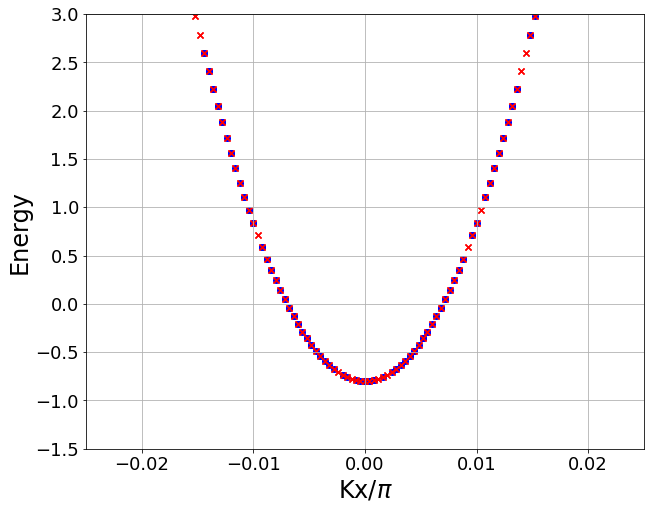

In [21]:
#alpha = 40 
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.ylim(ymin=-1.5)
plt.ylim(ymax=3)

plt.xlim(xmax = 0.025,xmin=-0.025)

#plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

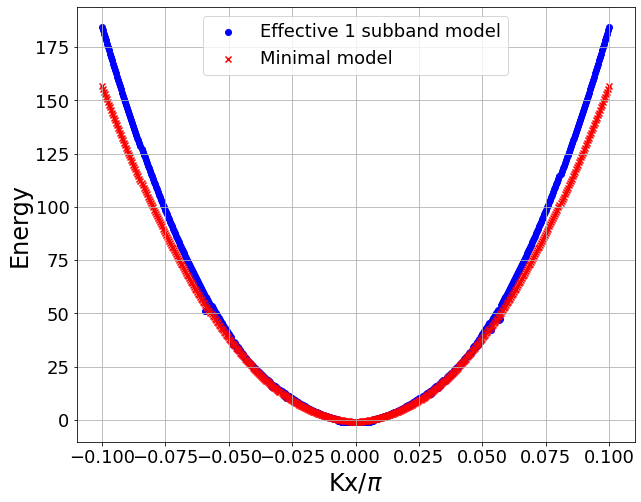

In [73]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

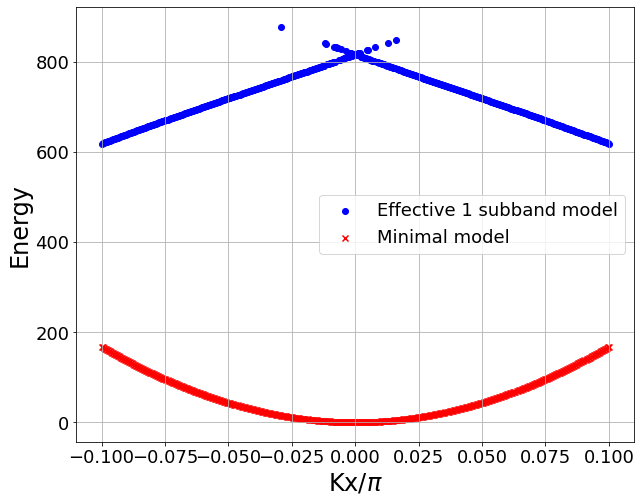

In [74]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,2], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,2], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

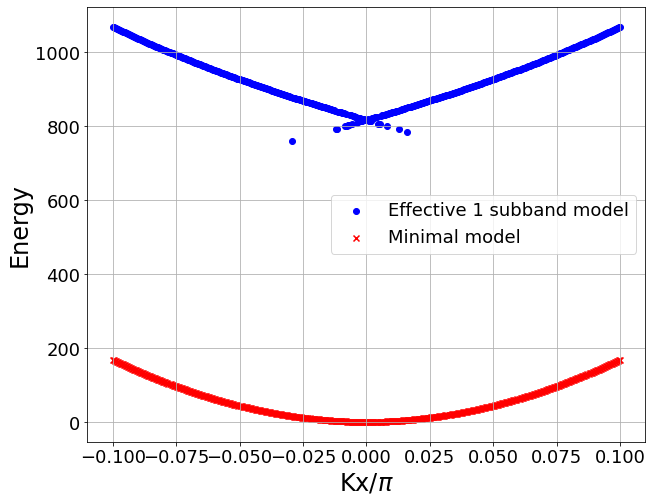

In [75]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,3], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,3], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')
plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

In [5]:
NSM = 3          # in nm
MY = 2              # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0          # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

MEFF = 0.023

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 3
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0
MU_SM =  0

MU_const = 0

ALPHAT = 20


first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919


In [6]:
NUM = 51
KX = np.linspace(-np.pi/6,np.pi/6,NUM)
Ep = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT, DELTA, MEFF,  MU_const,  phi=PHI, px=True, kx0=KX[i])

    Hli = Fli.H_p()

    Eli, Vli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=True)
        
    #Eli = np.sort(Eli)

    #print(Eli.shape)    
    #Eli = np.sort(Eli)
    
    Ep[i,:] = Eli

    if i%5 == 0:
        print(i)

0
5
10
15
20
25
30
35
40
45
50


In [7]:
NUM = 51
KX = np.linspace(-np.pi/6,np.pi/6,NUM)
EpM = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, px=True)
            
    Hli = Fli.HN(so = 'li', kx=KX[i])

    Eli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=False)
        
    Eli = np.sort(Eli)

    #print(Eli.shape)    
    #Eli = np.sort(Eli)
    
    EpM[i,:] = Eli

    if i%5 == 0:

        print(i)

0
5
10
15
20
25
30
35
40
45
50


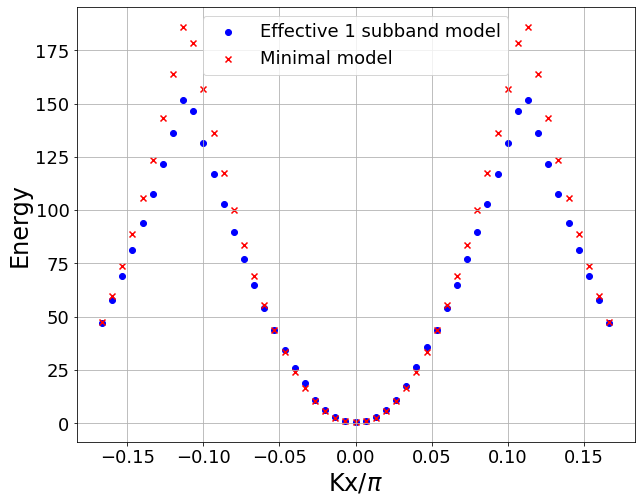

In [8]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

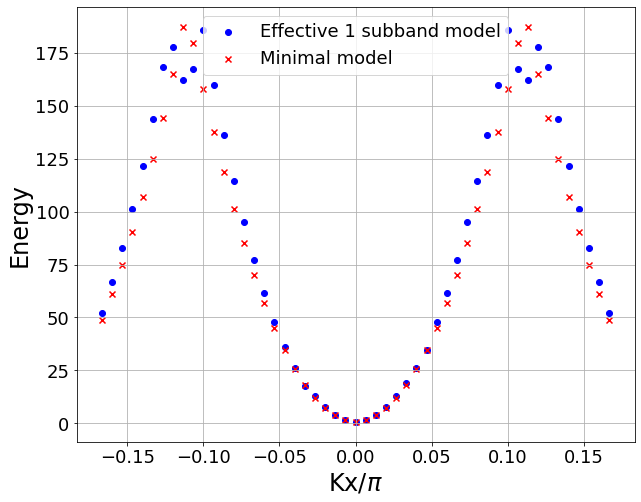

In [9]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

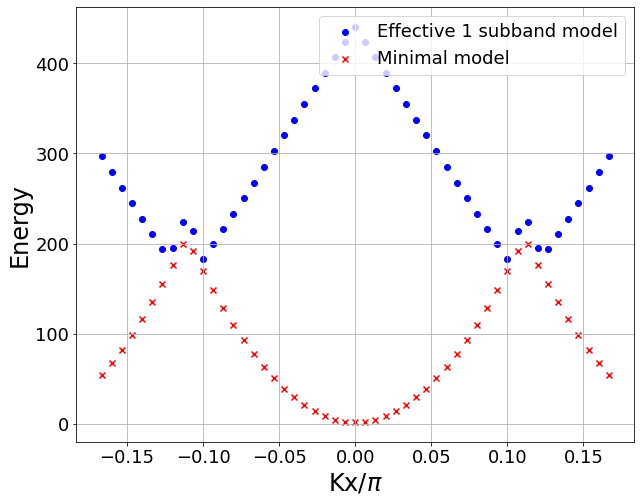

In [10]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,2], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,2], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

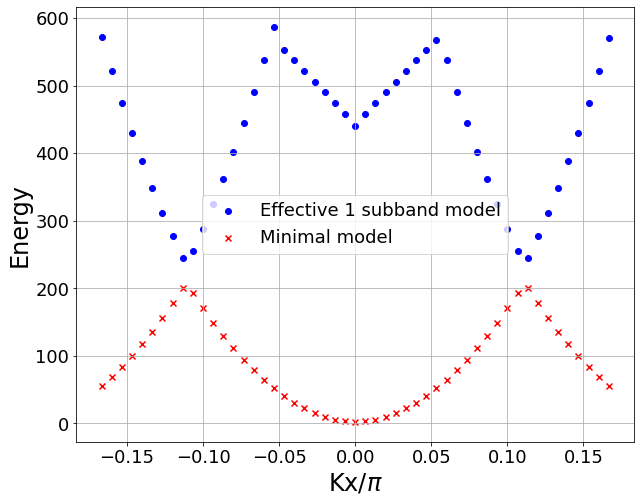

In [12]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,3], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,3], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

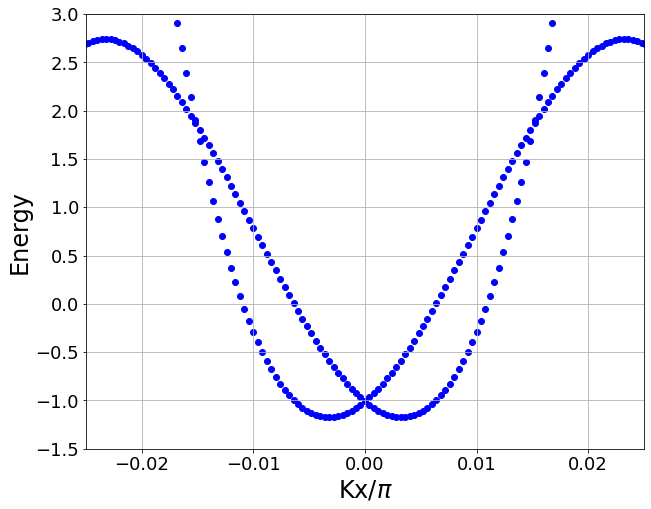

In [16]:
#alpha = 40 
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

#plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.ylim(ymin=-1.5)
plt.ylim(ymax=3)

plt.xlim(xmax = 0.025,xmin=-0.025)

#plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

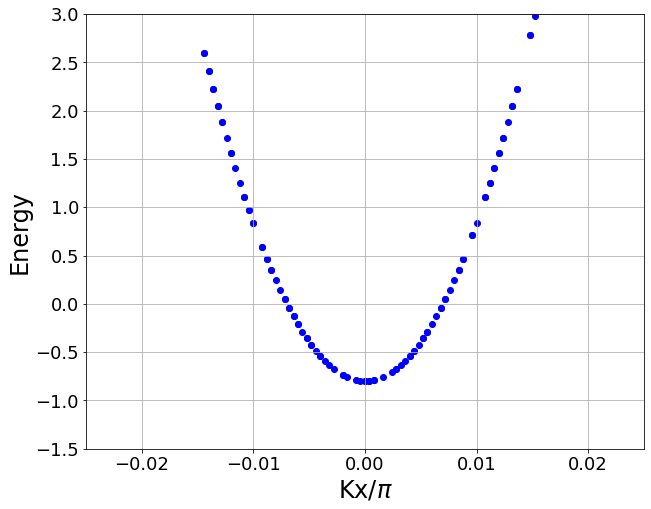

In [22]:
#alpha = 0 
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

#plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.ylim(ymin=-1.5)
plt.ylim(ymax=3)

plt.xlim(xmax = 0.025,xmin=-0.025)

#plt.legend(['Effective 1 subband model', 'Minimal model'])
plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)